In [1]:
%load_ext autoreload
%autoreload 2

from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm
import pyspedas
from pyspedas import get_data
from lunarmag import analyse_pass

REPO = Path.cwd().resolve().parent
RAW = REPO / 'data' / 'raw'
FIG = REPO / 'figures' / 'events'
FIG.mkdir(parents=True, exist_ok=True)

27-Nov-26 18:58:32: /Users/yulun/artemis-lunar-plasma/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm



Check load_pad matches plot:

27-Nov-26 19:02:11: File is current: themis_data/thb/l2/esd/2013/thb_l2_esa_peeb_20131204_v01.cdf
27-Nov-26 19:02:12: File is current: themis_data/thb/l2/fgm/2013/thb_l2_fgm_20131204_v01.cdf


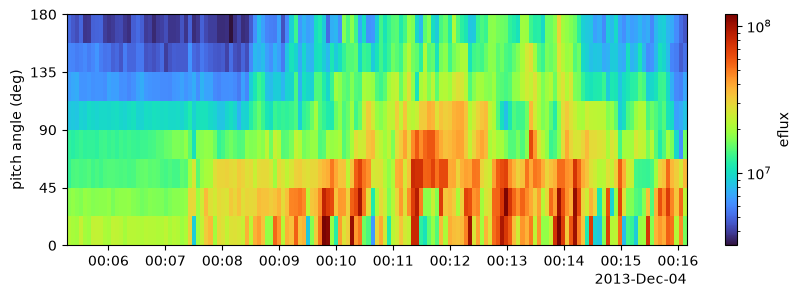

In [4]:
from lunarmag import load_pad
p = load_pad(['2013-12-04/00:05:20', '2013-12-04/00:16:10'], datatype='peeb', emin=30, emax=300)
fig, ax = plt.subplots(figsize=(10, 3))
pc = ax.pcolormesh(pd.to_datetime(p['t'], unit='s'), p['pa'], p['pad'].T, shading='nearest', cmap='turbo', norm=LogNorm())
ax.set_ylim(0, 180); ax.set_yticks([0, 45, 90, 135, 180]); ax.set_ylabel('pitch angle (deg)')
fig.colorbar(pc, ax=ax, label='eflux')